# LSTM-Based Sentiment Analysis

**Student Roll Number:** 24BAD039


To implement an LSTM neural network for sentiment analysis using the IMDB Movie Reviews dataset and classify reviews as positive or negative.



##Dataset Preparation

In [ ]:
!pip install -q importlib_resources

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras.layers import (
    TextVectorization, Embedding, LSTM, Dense, Dropout
)
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

# Load the IMDB dataset containing raw movie reviews
(train_raw, test_raw), info = tfds.load(
    "imdb_reviews",
    split=["train", "test"],
    as_supervised=True,
    with_info=True,
    batch_size=-1
)

# Convert TensorFlow tensors into NumPy arrays
X_train_all = train_raw[0].numpy()
y_train_all = train_raw[1].numpy()

X_test = test_raw[0].numpy()
y_test = test_raw[1].numpy()

print("Training samples:", len(X_train_all))
print("Testing samples:", len(X_test))
print("Class labels:", info.features["label"].names)

TensorFlow version: 2.21.0
Training samples: 25000
Testing samples: 25000
Class labels: ['neg', 'pos']


In [ ]:
# Decode reviews into readable text
reviews = [
    review.decode("utf-8")
    for review in X_train_all[:5]
]

labels = y_train_all[:5]

for i, (review, label) in enumerate(zip(reviews, labels), 1):
    sentiment = "Positive" if label == 1 else "Negative"
    print(f"\nReview {i} | Sentiment: {sentiment}")
    print(review[:300], "...")

print("\nTraining class distribution:")
print(pd.Series(y_train_all).value_counts().rename(
    index={0: "Negative", 1: "Positive"}
))


Review 1 | Sentiment: Negative
This was an absolutely terrible movie. Don't be lured in by Christopher Walken or Michael Ironside. Both are great actors, but this must simply be their worst role in history. Even their great acting could not redeem this movie's ridiculous storyline. This movie is an early nineties US propaganda pi ...

Review 2 | Sentiment: Negative
I have been known to fall asleep during films, but this is usually due to a combination of things including, really tired, being warm and comfortable on the sette and having just eaten a lot. However on this occasion I fell asleep because the film was rubbish. The plot development was constant. Cons ...

Review 3 | Sentiment: Negative
Mann photographs the Alberta Rocky Mountains in a superb fashion, and Jimmy Stewart and Walter Brennan give enjoyable performances as they always seem to do. <br /><br />But come on Hollywood - a Mountie telling the people of Dawson City, Yukon to elect themselves a marshal (yes a marshal!) an

In [21]:
# Split training data into training and validation sets
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_all
)

# Convert raw bytes into strings
X_train_text = np.array(
    [x.decode("utf-8") for x in X_train_text]
)
X_val_text = np.array(
    [x.decode("utf-8") for x in X_val_text]
)
X_test_text = np.array(
    [x.decode("utf-8") for x in X_test]
)

# Configure text preprocessing and vocabulary creation
MAX_WORDS = 10000
MAX_LENGTH = 250

vectorizer = TextVectorization(
    max_tokens=MAX_WORDS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

# Learn vocabulary only from training reviews
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train_text).batch(256)
)

# Convert reviews into padded integer sequences
X_train = vectorizer(X_train_text).numpy()
X_val = vectorizer(X_val_text).numpy()
X_test_seq = vectorizer(X_test_text).numpy()

vocabulary = vectorizer.get_vocabulary()

print("Vocabulary size:", len(vocabulary))
print("Maximum sequence length:", MAX_LENGTH)
print("Training sequence shape:", X_train.shape)
print("Validation sequence shape:", X_val.shape)
print("Testing sequence shape:", X_test_seq.shape)

print("\nSample tokens:", vocabulary[2:12])
print("\nSample numerical sequence:", X_train[0][:30])

Vocabulary size: 10000
Maximum sequence length: 250
Training sequence shape: (20000, 250)
Validation sequence shape: (5000, 250)
Testing sequence shape: (25000, 250)

Sample tokens: [np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this')]

Sample numerical sequence: [   2 2436   20   33    2 1938  175    1    1    7    4 2034   21   87
  479   12  609  565    3 6803  748   66 3025 1873 2023   79 3259  183
 1467   12]


##Implementing the LSTM Model

The model consists of an Embedding layer, an LSTM layer, a Dropout layer, and a Dense output layer with sigmoid activation for binary sentiment classification.

In [ ]:
model = Sequential([
    tf.keras.Input(shape=(MAX_LENGTH,)),
    Embedding(
        input_dim=len(vocabulary),
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

## Model training and performance evaluation

In [16]:
EPOCHS = 5
BATCH_SIZE = 64

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 93s 287ms/step - accuracy: 0.7541 - loss: 0.4875 - val_accuracy: 0.8518 - val_loss: 0.3658
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 269ms/step - accuracy: 0.8923 - loss: 0.2813 - val_accuracy: 0.8492 - val_loss: 0.3697
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 262ms/step - accuracy: 0.9189 - loss: 0.2175 - val_accuracy: 0.8546 - val_loss: 0.4018
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 266ms/step - accuracy: 0.9204 - loss: 0.2107 - val_accuracy: 0.8480 - val_loss: 0.4030
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 147s 282ms/step - accuracy: 0.9305 - loss: 0.1861 - val_accuracy: 0.8566 - val_loss: 0.3847


In [17]:
# Display final epoch metrics
results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Validation Accuracy",
        "Training Loss",
        "Validation Loss"
    ],
    "Value": [
        history.history["accuracy"][-1],
        history.history["val_accuracy"][-1],
        history.history["loss"][-1],
        history.history["val_loss"][-1]
    ]
})

print(results.to_string(index=False))

             Metric    Value
  Training Accuracy 0.930550
Validation Accuracy 0.856600
      Training Loss 0.186107
    Validation Loss 0.384738


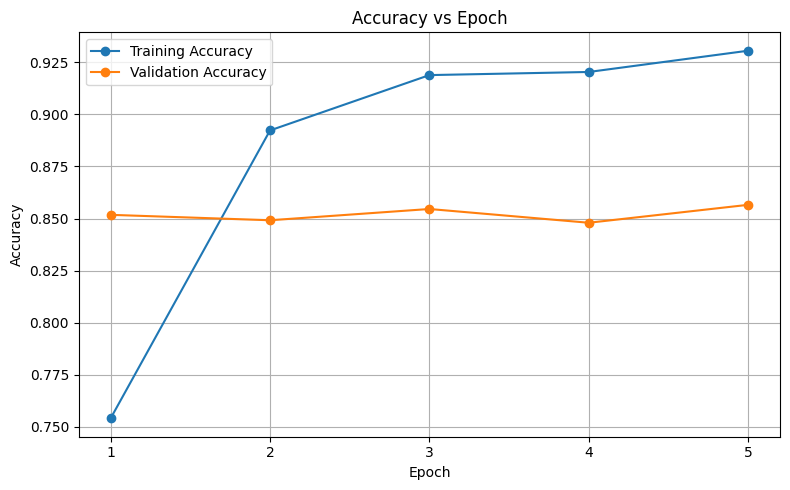

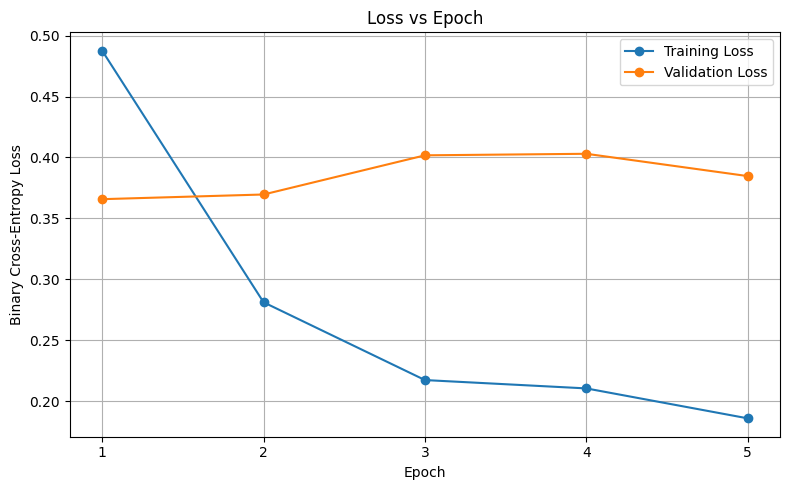

In [18]:
epochs_range = range(1, EPOCHS + 1)

# Accuracy vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"],
         marker="o", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"],
         marker="o", label="Validation Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["loss"],
         marker="o", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"],
         marker="o", label="Validation Loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

##Sentiment prediction and experiment management

In [18]:
# New reviews not used during training
sample_reviews = [
    "This movie was fantastic. The acting and story were excellent.",
    "I hated this film. It was boring and poorly directed.",
    "The performances were wonderful and I really enjoyed the movie.",
    "The story was terrible and the ending was disappointing.",
    "The movie was okay, but some scenes were too slow."
]

# Expected labels are for comparison only, not model input
expected_sentiments = [
    "Positive",
    "Negative",
    "Positive",
    "Negative",
    "Negative"
]

# Use the SAME vectorizer fitted on the training reviews
sample_sequences = vectorizer(
    tf.constant(sample_reviews)
).numpy()

# Predict sentiment probabilities
probabilities = model.predict(sample_sequences, verbose=0).ravel()

predicted_sentiments = [
    "Positive" if p >= 0.5 else "Negative"
    for p in probabilities
]

# Display results
prediction_results = pd.DataFrame({
    "Review": sample_reviews,
    "Expected Sentiment": expected_sentiments,
    "Predicted Sentiment": predicted_sentiments,
    "Positive Probability": np.round(probabilities, 4)
})

print(prediction_results.to_string(index=False))

In [20]:
for review, expected, predicted, prob in zip(
    sample_reviews,
    expected_sentiments,
    predicted_sentiments,
    probabilities
):
    result = "Correct" if expected == predicted else "Incorrect"

    print("\nReview:", review)
    print("Expected:", expected)
    print("Predicted:", predicted)
    print(f"Positive probability: {prob:.4f}")
    print("Comparison:", result)

                                                         Review Expected Sentiment Predicted Sentiment  Positive Probability
 This movie was fantastic. The acting and story were excellent.           Positive            Positive                0.9090
          I hated this film. It was boring and poorly directed.           Negative            Negative                0.0036
The performances were wonderful and I really enjoyed the movie.           Positive            Positive                0.9707
       The story was terrible and the ending was disappointing.           Negative            Negative                0.0189
             The movie was okay, but some scenes were too slow.           Negative            Negative                0.0217
